# Unidad III – Análisis supervisado
## Implementación y evaluación de modelos de regresión y clasificación

| | |
|---|---|
| **Alumna** | Brisa Adriana Mendoza Vigueras · 10IDGS-G1 |
| **Proyecto** | Análisis del rendimiento académico de estudiantes |
| **Datos** | `data/processed/student_por_modelo.csv`, generado por el ETL de la Unidad II |

**Pregunta del proyecto (Unidad I):** ¿Qué factores influyen en la calificación final de los estudiantes y en qué
medida es posible **predecir esa calificación** y **anticipar el riesgo de reprobación**?

En este notebook se construyen dos tipos de modelos:

- **Regresión:** predice la calificación final `G3` (un número de 0 a 20).
- **Clasificación:** predice si el alumno será *Aprobado* (G3 ≥ 10) o *No aprobado* (G3 < 10).

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, make_scorer, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

FIG = Path("../docs/figuras")
MODELOS = Path("../modelos")
PROCESSED = Path("../data/processed")
MODELOS.mkdir(exist_ok=True)
SEMILLA = 42   # fija el azar para que los resultados se repitan igual cada vez

## Parte A. Preparación de los datos

### A.1 Cargar el dataset procesado

Se usa el archivo generado por el ETL de la Unidad II, que ya está **limpio y codificado**:

- Contiene **634 alumnos**: se excluyeron los 15 abandonos (G3 = 0 con 0 faltas).
- Todas las variables son numéricas: las binarias ya están en 0/1 y las nominales en one-hot.
- Las faltas están recortadas a 15.
- Incluye la columna `aprobado`: 1 si G3 ≥ 10 y 0 si no.

In [2]:
df = pd.read_csv(PROCESSED / "student_por_modelo.csv")
df.shape

(634, 44)

In [3]:
df["aprobado"].value_counts()

aprobado
1    549
0     85
Name: count, dtype: int64

Hay 549 aprobados y **85 no aprobados (13.4 %)**. Las clases están **desbalanceadas**, y eso se considera
en la división de los datos y al entrenar los clasificadores.

### A.2 Variables objetivo (y)

| Tarea | Variable objetivo | Por qué |
|---|---|---|
| Regresión | `G3` | Es la calificación final, el resultado que se quiere anticipar |
| Clasificación | `aprobado` | Responde directamente a la pregunta “¿este alumno está en riesgo de reprobar?” |

In [4]:
y_reg = df["G3"]
y_clf = df["aprobado"]

### A.3 Variables predictoras (X): tres escenarios

Las calificaciones parciales (`G1`, `G2`) están muy relacionadas con `G3` (correlación de 0.83 y 0.92). Usarlas
mejora mucho la predicción, pero cuanto más tarde se conocen, **menos tiempo queda para ayudar al alumno**. Por eso
se comparan tres escenarios que representan tres momentos del curso:

| Escenario | Variables X | Momento del curso | Utilidad |
|---|---|---|---|
| **1. Inicio** | Variables personales, familiares y sociales (sin G1 ni G2) | Al inscribirse | Máxima anticipación, pero menos información |
| **2. Alerta temprana** | Escenario 1 + `G1` | Después del primer periodo | **Equilibrio entre anticipación y precisión. Es el escenario principal del proyecto** |
| **3. Final** | Escenario 1 + `G1` + `G2` | Después del segundo periodo | Máxima precisión, pero casi no queda tiempo para intervenir (fuga de información) |

En ningún escenario se usan `G3`, `aprobado` ni `id_estudiante` como predictoras: las dos primeras son la respuesta
y la tercera solo es un identificador.

In [5]:
no_predictoras = ["id_estudiante", "G3", "aprobado"]
X_final = df.drop(columns=no_predictoras)
X_temprana = X_final.drop(columns=["G2"])
X_inicio = X_final.drop(columns=["G1", "G2"])

escenarios = {
    "1. Inicio": X_inicio,
    "2. Alerta temprana": X_temprana,
    "3. Final": X_final,
}
pd.Series({nombre: X.shape[1] for nombre, X in escenarios.items()}, name="num_variables")

1. Inicio             39
2. Alerta temprana    40
3. Final              41
Name: num_variables, dtype: int64

### A.4 Separar entrenamiento y prueba

- **80 % entrenamiento:** los datos con los que el modelo aprende.
- **20 % prueba:** alumnos que el modelo **nunca vio**, con los que se mide qué tan bien funciona en la realidad.
- `stratify=y_clf` mantiene la misma proporción de aprobados y no aprobados en ambos grupos.
- Se separan los **índices** de los alumnos, para usar exactamente los mismos alumnos de prueba en todos los
  escenarios y modelos. Así la comparación es justa.

In [6]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=SEMILLA, stratify=y_clf)
pd.Series({
    "entrenamiento": len(idx_train),
    "prueba": len(idx_test),
    "no aprobados en prueba": (y_clf.loc[idx_test] == 0).sum(),
})

entrenamiento             507
prueba                    127
no aprobados en prueba     17
dtype: int64

### A.5 Escalamiento

La **regresión lineal** y la **regresión logística** son sensibles a la escala de las variables (por ejemplo, `absences`
va de 0 a 15 y `studytime` de 1 a 4). Por eso se usa un **Pipeline**, que primero aplica `StandardScaler` (media 0,
desviación 1) y después entrena el modelo.

El escalador se ajusta **solo con los datos de entrenamiento**, para que no se filtre información del conjunto de
prueba. Los árboles y Random Forest no necesitan escalamiento, porque dividen los datos con preguntas del tipo
“¿failures > 0?”.

## Parte B. Regresión: predecir la calificación final (G3)

Se prueban dos algoritmos:

- **Regresión lineal:** busca la mejor combinación lineal de las variables. Es simple, rápida e interpretable;
  es el modelo base.
- **Random Forest Regressor:** combina 300 árboles de decisión y promedia sus predicciones. Capta relaciones no lineales.

**Métricas:**

| Métrica | Qué mide | Cómo leerla |
|---|---|---|
| **MAE** | Error absoluto medio: en promedio, por cuántos puntos se equivoca | Menor es mejor. MAE = 1 significa ±1 punto de 20 |
| **RMSE** | Raíz del error cuadrático medio; castiga más los errores grandes | Menor es mejor; está en puntos de calificación |
| **R²** | Proporción de la variación de G3 que explica el modelo | De 0 a 1; más cerca de 1 es mejor |

In [7]:
def evaluar_regresion(modelo, X):
    modelo.fit(X.loc[idx_train], y_reg.loc[idx_train])
    pred = modelo.predict(X.loc[idx_test])
    real = y_reg.loc[idx_test]
    return {
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "R2": r2_score(real, pred),
    }


modelos_regresion = {
    "Regresión lineal": lambda: Pipeline([("escala", StandardScaler()), ("modelo", LinearRegression())]),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, random_state=SEMILLA),
}

filas = []
for escenario, X in escenarios.items():
    for nombre, crear_modelo in modelos_regresion.items():
        filas.append({"escenario": escenario, "modelo": nombre, **evaluar_regresion(crear_modelo(), X)})

resultados_regresion = pd.DataFrame(filas).round(3)
resultados_regresion

,escenario,modelo,MAE,RMSE,R2
0,1. Inicio,Regresión lineal,1.713,2.161,0.224
1,1. Inicio,Random Forest,1.555,1.974,0.352
2,2. Alerta temprana,Regresión lineal,1.024,1.284,0.726
3,2. Alerta temprana,Random Forest,0.989,1.247,0.742
4,3. Final,Regresión lineal,0.648,0.801,0.893
5,3. Final,Random Forest,0.605,0.780,0.899


**Interpretación de la regresión:**

| Escenario | Mejor modelo | MAE | R² | Lectura |
|---|---|---|---|---|
| 1. Inicio | Random Forest | 1.56 | 0.35 | Se equivoca por ±1.6 puntos y explica solo el 35 % de la variación. Los factores personales y sociales influyen, pero **no bastan** para predecir con precisión |
| 2. Alerta temprana | Random Forest | 0.99 | 0.74 | Con G1, el error baja a ±1 punto y explica el 74 %. **Cumple el criterio de éxito de la Unidad I (R² ≥ 0.70)** |
| 3. Final | Random Forest | 0.61 | 0.90 | Casi perfecto, pero cuando ya se conoce G2 queda poco tiempo para ayudar al alumno |

- Random Forest supera ligeramente a la regresión lineal en los tres escenarios, porque capta relaciones no lineales.
- El salto más grande ocurre al agregar G1 (de R² 0.35 a 0.74): **el desempeño del primer periodo es el mejor
  indicador temprano** de cómo terminará el alumno.
- **Utilidad:** con el escenario 2, al terminar el primer periodo la escuela puede estimar la calificación final de
  cada alumno con un margen de ±1 punto y priorizar a quienes se proyecten cerca o debajo de 10.

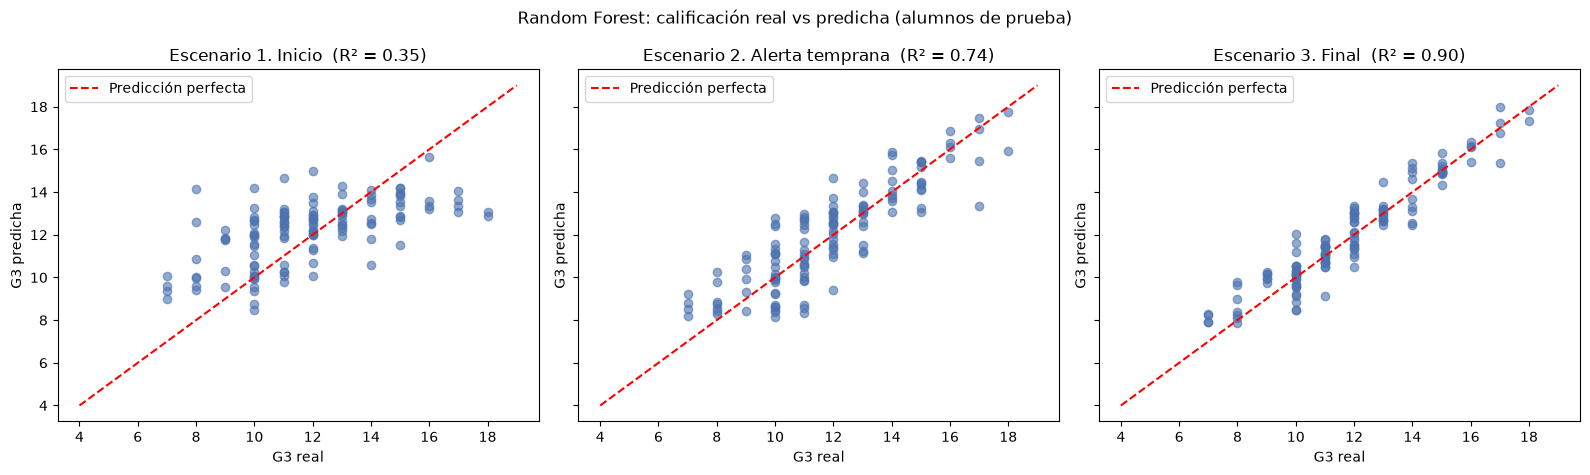

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, (escenario, X) in zip(axes, escenarios.items()):
    modelo = RandomForestRegressor(n_estimators=300, random_state=SEMILLA)
    modelo.fit(X.loc[idx_train], y_reg.loc[idx_train])
    pred = modelo.predict(X.loc[idx_test])
    ax.scatter(y_reg.loc[idx_test], pred, alpha=0.6, color="#4C72B0")
    ax.plot([4, 19], [4, 19], color="red", linestyle="--", label="Predicción perfecta")
    ax.set_title(f"Escenario {escenario}  (R² = {r2_score(y_reg.loc[idx_test], pred):.2f})")
    ax.set_xlabel("G3 real")
    ax.set_ylabel("G3 predicha")
    ax.legend()
plt.suptitle("Random Forest: calificación real vs predicha (alumnos de prueba)")
plt.tight_layout()
plt.savefig(FIG / "u3_regresion_real_vs_predicha.png", dpi=120)
plt.show()

**Interpretación de la gráfica:** cada punto es un alumno de prueba. Si el modelo acertara perfecto, todos los puntos
estarían sobre la línea roja. En el escenario 1 los puntos están muy dispersos, porque el modelo casi siempre
predice valores cercanos al promedio. En los escenarios 2 y 3 los puntos se acercan a la diagonal: conocer la
calificación de los periodos anteriores mejora mucho la predicción.

## Parte C. Clasificación: anticipar quién no aprobará

Se prueban tres algoritmos:

- **Regresión logística:** a pesar del nombre, es un clasificador. Calcula la probabilidad de cada clase.
- **Árbol de decisión:** una serie de preguntas sí/no, como “¿G1 < 10?” o “¿failures > 0?”. Es fácil de explicar.
- **Random Forest:** muchos árboles que votan.

Los tres usan `class_weight="balanced"`, que le da más peso a la clase minoritaria (no aprobados) para que el modelo
no la ignore.

**Métricas** (calculadas para la clase **No aprobado**, que es la que interesa detectar):

| Métrica | Pregunta que responde |
|---|---|
| **Accuracy** | ¿Qué porcentaje del total clasificó bien? (engañosa con clases desbalanceadas) |
| **Precision** | De los que el modelo marcó como “no aprobará”, ¿cuántos realmente no aprobaron? |
| **Recall** | De los que realmente no aprobaron, ¿a cuántos detectó? **Es la más importante aquí** |
| **F1-score** | Equilibrio entre precision y recall |

In [9]:
def evaluar_clasificacion(modelo, X):
    modelo.fit(X.loc[idx_train], y_clf.loc[idx_train])
    pred = modelo.predict(X.loc[idx_test])
    real = y_clf.loc[idx_test]
    return {
        "Accuracy": accuracy_score(real, pred),
        "Precision": precision_score(real, pred, pos_label=0),
        "Recall": recall_score(real, pred, pos_label=0),
        "F1": f1_score(real, pred, pos_label=0),
    }


modelos_clasificacion = {
    "Regresión logística": lambda: Pipeline([("escala", StandardScaler()),
                                             ("modelo", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Árbol de decisión": lambda: DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEMILLA),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEMILLA),
}

filas = []
for escenario, X in escenarios.items():
    for nombre, crear_modelo in modelos_clasificacion.items():
        filas.append({"escenario": escenario, "modelo": nombre, **evaluar_clasificacion(crear_modelo(), X)})

resultados_clasificacion = pd.DataFrame(filas).round(3)
resultados_clasificacion

,escenario,modelo,Accuracy,Precision,Recall,F1
0,1. Inicio,Regresión logística,0.732,0.270,0.588,0.370
1,1. Inicio,Árbol de decisión,0.701,0.244,0.588,0.345
2,1. Inicio,Random Forest,0.843,0.412,0.412,0.412
3,2. Alerta temprana,Regresión logística,0.787,0.333,0.588,0.426
4,2. Alerta temprana,Árbol de decisión,0.819,0.406,0.765,0.531
5,2. Alerta temprana,Random Forest,0.850,0.450,0.529,0.486
6,3. Final,Regresión logística,0.850,0.458,0.647,0.537
7,3. Final,Árbol de decisión,0.866,0.500,0.765,0.605
8,3. Final,Random Forest,0.874,0.526,0.588,0.556


**Interpretación de la clasificación:**

- **La accuracy engaña:** en el escenario 1, Random Forest tiene 84 % de accuracy pero solo detecta al 41 % de los no
  aprobados. Como el 87 % aprueba, acertar “aprobado” es fácil. Por eso se prioriza el **recall** de la clase
  “No aprobado”.
- **Escenario 1 (inicio):** el mejor recall es 0.59, con precision de 0.27 a 0.41. Detecta a algunos alumnos en
  riesgo, pero genera muchas falsas alarmas.
- **Escenario 2 (alerta temprana):** el árbol de decisión detecta 13 de 17 no aprobados (recall 0.76). Random
  Forest, sin ajustar, solo detecta 9 (recall 0.53); por eso se optimiza en la Parte D.
- **Escenario 3 (final):** mejora un poco la precision, pero casi no aporta recall frente al escenario 2. Esperar a
  G2 no compensa perder un periodo de intervención.

## Parte D. Evaluación y mejora

### D.1 Optimización de hiperparámetros con GridSearchCV

Los modelos tienen “perillas” de configuración (**hiperparámetros**), por ejemplo la profundidad máxima de los árboles.
`GridSearchCV` prueba todas las combinaciones de una lista y elige la mejor usando **validación cruzada de 5
particiones**: divide el entrenamiento en 5 partes, entrena con 4, evalúa con la restante y repite 5 veces. Así la
elección no depende de la suerte de una sola división.

La optimización se aplica al **escenario 2 (alerta temprana)**, el principal del proyecto:

- **Regresión:** se busca el menor MAE.
- **Clasificación:** se busca el mayor F1 de la clase “No aprobado”, que equilibra detectar a los alumnos en
  riesgo sin generar demasiadas falsas alarmas.

In [10]:
X = X_temprana
X_train, X_test = X.loc[idx_train], X.loc[idx_test]

busqueda_reg = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=SEMILLA),
    param_grid={"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5, 10]},
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA),
)
busqueda_reg.fit(X_train, y_reg.loc[idx_train])
mejor_regresor = busqueda_reg.best_estimator_
busqueda_reg.best_params_

{'max_depth': None, 'min_samples_leaf': 10}

In [11]:
pred_reg = mejor_regresor.predict(X_test)
antes = resultados_regresion.query("escenario == '2. Alerta temprana' and modelo == 'Random Forest'").iloc[0]
pd.DataFrame({
    "Random Forest original": antes[["MAE", "RMSE", "R2"]].astype(float),
    "Random Forest optimizado": [mean_absolute_error(y_reg.loc[idx_test], pred_reg),
                                 np.sqrt(mean_squared_error(y_reg.loc[idx_test], pred_reg)),
                                 r2_score(y_reg.loc[idx_test], pred_reg)],
}).round(3)

,Random Forest original,Random Forest optimizado
MAE,0.989,0.949
RMSE,1.247,1.179
R2,0.742,0.769


**Resultado de la optimización (regresión):** la mejor configuración es `min_samples_leaf = 10`, es decir, cada hoja
del árbol debe tener al menos 10 alumnos. Esto evita que los árboles “memoricen” casos individuales (sobreajuste).

- El MAE baja de 0.99 a **0.95** puntos.
- El R² sube de 0.74 a **0.77**.

Este es el **modelo de regresión final** del proyecto.

In [12]:
f1_no_aprobado = make_scorer(f1_score, pos_label=0)

busqueda_clf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEMILLA),
    param_grid={"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5, 10]},
    scoring=f1_no_aprobado,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA),
)
busqueda_clf.fit(X_train, y_clf.loc[idx_train])
mejor_clasificador = busqueda_clf.best_estimator_
busqueda_clf.best_params_

{'max_depth': 3, 'min_samples_leaf': 10}

In [13]:
pred_clf = mejor_clasificador.predict(X_test)
real_clf = y_clf.loc[idx_test]
antes = resultados_clasificacion.query("escenario == '2. Alerta temprana' and modelo == 'Random Forest'").iloc[0]
pd.DataFrame({
    "Random Forest original": antes[["Accuracy", "Precision", "Recall", "F1"]].astype(float),
    "Random Forest optimizado": [accuracy_score(real_clf, pred_clf),
                                 precision_score(real_clf, pred_clf, pos_label=0),
                                 recall_score(real_clf, pred_clf, pos_label=0),
                                 f1_score(real_clf, pred_clf, pos_label=0)],
}).round(3)

,Random Forest original,Random Forest optimizado
Accuracy,0.850,0.827
Precision,0.450,0.424
Recall,0.529,0.824
F1,0.486,0.560


**Resultado de la optimización (clasificación):** la mejor configuración usa árboles poco profundos (`max_depth = 3`)
con al menos 10 alumnos por hoja. Son modelos más simples que generalizan mejor.

- El **recall de “No aprobado” sube de 0.53 a 0.82**: ahora detecta a 14 de los 17 alumnos que no aprobaron.
- El F1 sube de 0.49 a 0.56. La accuracy baja un poco (de 0.85 a 0.83), porque el modelo ahora marca más alumnos
  como “en riesgo”. Es un intercambio aceptable para el objetivo del proyecto.
- **Cumple el criterio de éxito de la Unidad I (recall ≥ 0.70).** Este es el **modelo de clasificación final**.

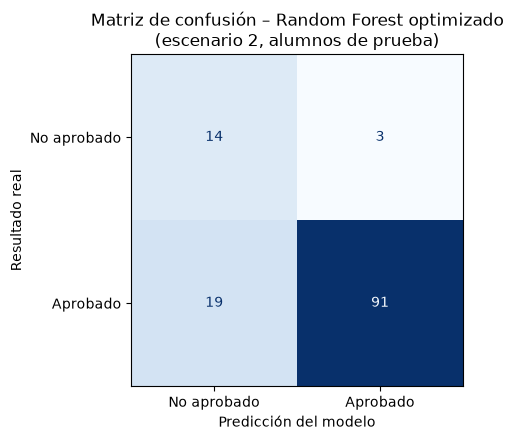

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(real_clf, pred_clf, labels=[0, 1]),
                       display_labels=["No aprobado", "Aprobado"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión – Random Forest optimizado\n(escenario 2, alumnos de prueba)")
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Resultado real")
plt.tight_layout()
plt.savefig(FIG / "u3_matriz_confusion.png", dpi=120)
plt.show()

In [15]:
print(classification_report(real_clf, pred_clf, target_names=["No aprobado", "Aprobado"]))

              precision    recall  f1-score   support

 No aprobado       0.42      0.82      0.56        17
    Aprobado       0.97      0.83      0.89       110

    accuracy                           0.83       127
   macro avg       0.70      0.83      0.73       127
weighted avg       0.90      0.83      0.85       127



**Interpretación de la matriz de confusión (127 alumnos de prueba):**

| | Predicho: No aprobado | Predicho: Aprobado |
|---|---|---|
| **Real: No aprobado (17)** | **14 – riesgo detectado** ✔ | 3 – riesgo no detectado ✘ (error grave) |
| **Real: Aprobado (110)** | 19 – falsa alarma ✘ (error leve) | **91 – aprobado correcto** ✔ |

- **Errores graves (3):** alumnos que reprobaron sin que el modelo lo anticipara. Son el error más costoso, porque no
  recibirían apoyo. El modelo los mantiene en un número bajo.
- **Falsas alarmas (19):** alumnos que sí aprobaron pero fueron marcados en riesgo. Su costo es bajo: recibirían una
  tutoría que quizá no necesitaban.
- **Utilidad:** de 127 alumnos, el modelo sugeriría dar seguimiento a 33, y ahí estarían 14 de los 17 que de verdad
  lo necesitaban. Es mucho más eficiente que dar tutoría a todos, o que esperar a que reprueben.

### D.2 ¿Qué variables son relevantes?

Random Forest calcula la **importancia** de cada variable: cuánto ayuda a reducir el error cuando el modelo la usa
para dividir a los alumnos.

- En el **escenario 2**, G1 domina por mucho.
- Para saber qué factores **no académicos** influyen, se analiza el **escenario 1**, que no tiene calificaciones.

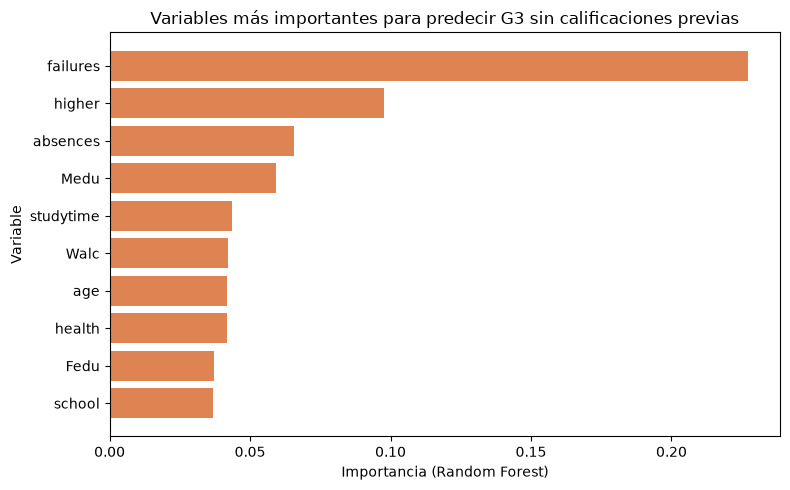

,Escenario 1 (sin calificaciones),Escenario 2 (con G1)
failures,0.227,0.008
higher,0.098,0.000
absences,0.066,0.005
Medu,0.059,0.003
studytime,0.043,0.001
Walc,0.042,0.004
age,0.042,0.015
health,0.042,0.006
Fedu,0.037,0.003
school,0.037,0.004


In [16]:
modelo_inicio = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEMILLA)
modelo_inicio.fit(X_inicio.loc[idx_train], y_reg.loc[idx_train])

importancias = pd.DataFrame({
    "Escenario 1 (sin calificaciones)": pd.Series(modelo_inicio.feature_importances_, X_inicio.columns),
    "Escenario 2 (con G1)": pd.Series(mejor_regresor.feature_importances_, X_temprana.columns),
}).fillna(0)

top = importancias["Escenario 1 (sin calificaciones)"].sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#DD8452")
ax.set_title("Variables más importantes para predecir G3 sin calificaciones previas")
ax.set_xlabel("Importancia (Random Forest)")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.savefig(FIG / "u3_importancia_variables.png", dpi=120)
plt.show()

importancias.sort_values("Escenario 1 (sin calificaciones)", ascending=False).head(10).round(3)

**Variables relevantes:**

- **Con G1 (escenario 2):** la calificación del primer periodo concentra casi toda la importancia. El desempeño
  previo es el mejor predictor del desempeño final.
- **Sin calificaciones (escenario 1):**
  1. **`failures`** (materias reprobadas antes) es por mucho el factor más importante: duplica al segundo.
  2. **`higher`** (querer estudiar la universidad): la motivación y las metas importan.
  3. **`absences`** (faltas).
  4. **`Medu`** (escolaridad de la madre).
  5. **`studytime`** (tiempo de estudio).
  6. Consumo de alcohol en fin de semana (**`Walc`**), edad, salud y escuela.
- Esto **coincide con el análisis exploratorio de la Unidad II**: `failures` tenía la correlación más fuerte con G3
  (−0.39), y los alumnos que quieren estudios superiores promediaban unos 3 puntos más.
- **Relación con el problema:** los factores que más pesan son detectables desde la inscripción (historial de
  reprobación, metas, asistencia). La escuela puede usarlos para ubicar a los alumnos en riesgo antes de que haya
  calificaciones, y confirmar con G1 al terminar el primer periodo.

### D.3 Guardar los modelos y las predicciones

- Los modelos optimizados se guardan en `modelos/` con `joblib`, para reutilizarlos sin volver a entrenar.
- Las predicciones de los alumnos de prueba y las métricas se guardan en `data/processed/`, para usarlas en el
  dashboard de Power BI (Unidad V).

In [17]:
joblib.dump(mejor_regresor, MODELOS / "rf_regresion_G3_alerta_temprana.joblib")
joblib.dump(mejor_clasificador, MODELOS / "rf_clasificacion_aprobado_alerta_temprana.joblib")

predicciones = pd.DataFrame({
    "id_estudiante": df.loc[idx_test, "id_estudiante"],
    "G3_real": y_reg.loc[idx_test],
    "G3_predicha": pred_reg.round(2),
    "error_absoluto": np.abs(y_reg.loc[idx_test] - pred_reg).round(2),
    "aprobado_real": real_clf,
    "aprobado_predicho": pred_clf,
    "prob_no_aprobar": mejor_clasificador.predict_proba(X_test)[:, 0].round(3),
})
predicciones["resultado"] = np.select(
    [(predicciones.aprobado_real == 0) & (predicciones.aprobado_predicho == 0),
     (predicciones.aprobado_real == 1) & (predicciones.aprobado_predicho == 0),
     (predicciones.aprobado_real == 0) & (predicciones.aprobado_predicho == 1)],
    ["Riesgo detectado", "Falsa alarma", "Riesgo no detectado"], default="Aprobado correcto")
predicciones.to_csv(PROCESSED / "predicciones_supervisado.csv", index=False)

metricas = pd.concat([resultados_regresion.assign(tarea="Regresión"),
                      resultados_clasificacion.assign(tarea="Clasificación")])
metricas.to_csv(PROCESSED / "metricas_supervisado.csv", index=False)
predicciones["resultado"].value_counts()

resultado
Aprobado correcto      91
Falsa alarma           19
Riesgo detectado       14
Riesgo no detectado     3
Name: count, dtype: int64

## Conclusiones de la Unidad III

1. **Se puede predecir la calificación final con buena precisión desde el primer periodo.**
   - Random Forest optimizado (escenario 2) obtiene MAE = 0.95 y R² = 0.77.
   - Al inicio del curso, sin calificaciones, la predicción es débil (R² = 0.35).
2. **Se puede anticipar el riesgo de reprobación.**
   - El clasificador optimizado detecta al 82 % de los alumnos que no aprobarán (14 de 17), con 19 falsas alarmas
     de 127.
   - Para un sistema de alerta temprana es preferible una falsa alarma que un alumno en riesgo sin detectar.
3. **Factores más influyentes:** reprobaciones previas, aspiración a estudios superiores, faltas, escolaridad de la
   madre y tiempo de estudio. Una vez que existe, la calificación del primer periodo (G1) supera a todos.
4. **Ajustes que funcionaron:**
   - Ponderar las clases (`class_weight="balanced"`).
   - Limitar la complejidad de los árboles con GridSearchCV y validación cruzada. Esto subió el recall de 0.53 a 0.82.
5. **Criterios de éxito de la Unidad I:** se cumplen los dos (R² ≥ 0.70 y recall ≥ 0.70) en el escenario de alerta
   temprana.

**Limitaciones:**
- El conjunto de prueba es pequeño (17 no aprobados), así que las métricas pueden variar con otra división.
- Los datos son de dos escuelas portuguesas de 2005-2006, por lo que las conclusiones no se generalizan
  automáticamente.
- Correlación no implica causalidad.

**Archivos generados:**
- `modelos/rf_regresion_G3_alerta_temprana.joblib`
- `modelos/rf_clasificacion_aprobado_alerta_temprana.joblib`
- `data/processed/predicciones_supervisado.csv`
- `data/processed/metricas_supervisado.csv`
- Las gráficas `docs/figuras/u3_*.png`